In [1]:
import config as c
import pandas as pd
import numpy as np
import seaborn as sns
import mne
import matplotlib.pyplot as plt
from lib import *

This notebook implements MVAR modeling per window (epoch) which is an instance in the bag (exam) during [MIL](https://torchmil.readthedocs.io/en/main/). Each window:
- is z-scored
- has AR coefficients computed
- has H computed (from AR)
- has NDTF & ffDTF computed and aggregated per freqiency bands (sum or average)
- has heatmap, "circle" form mne-connectivity and graph representation

In graph domain each window can be represented band-wise as:
- dense graphs (that can have traditional graph analysis metrics compueted)
- sparse graphs (choosing only the strongest connections in reference to all or band-local)

The graphs have positions set to the applied standard 1020 montage to see the effective connectivity more intuitively on the scalp-sensor space.

It seems that the spase graphs in global mode can be a good candidate for window graph representation for graph NNs implemented from [PyG](https://pytorch-geometric.readthedocs.io/en/latest/).

All functions with documentation are in the library (lib.py) and all constants are in configuration file (config.py).

The aim is to investigate if effective (causal) connectivity (explicitly not-normalised DTF (NDTF) and full-frequency normalised DTF (ffDTF)) can be represented as a graph. The study also checks if the representation can be sparsed to discard week connections, that instead of being real direct connections, act as noise.

In [19]:
fpr = load_memmap()
single_exam = fpr[5700] #randomly pick a recording

In [20]:
#sanity check
#single_exam.shape

Not setting metadata
150 matching events found
No baseline correction applied
0 projection items activated


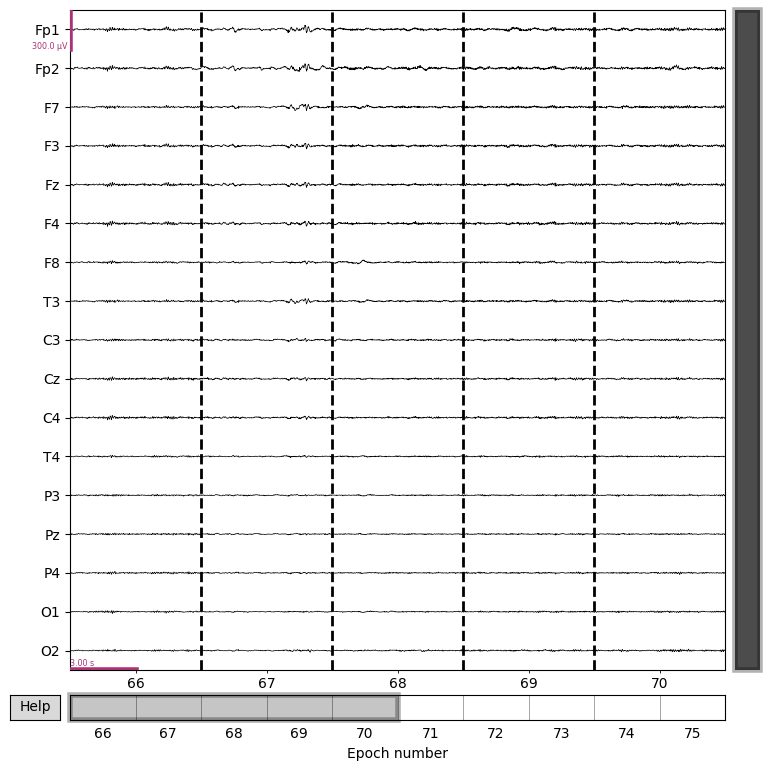

In [22]:
g = plot_epoch_eeg(single_exam, start_epoch = 66, end_epoch = 76, n_epochs_to_plot = 5, scalings = dict(eeg=150e-6))

In [10]:
one_window = single_exam[6, :, :]

Creating RawArray with float64 data, n_channels=17, n_times=768
    Range : 0 ... 767 =      0.000 ...     5.992 secs
Ready.


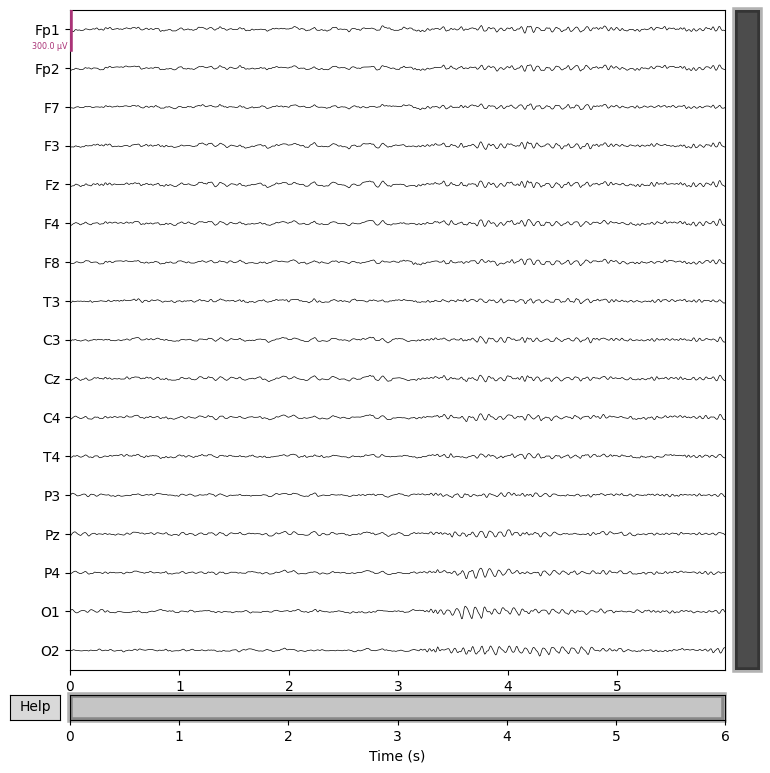

In [11]:
g = plot_one_window(one_window, scalings = dict(eeg=150e-6))

# prepare for modelling

In [12]:
one_window_zscored = zscore_per_channel(one_window)
one_window_zscored

array([[-1.446755  , -1.5302458 , -1.5347456 , ..., -0.97855765,
        -1.3294239 , -1.027504  ],
       [-1.8480396 , -2.0503657 , -1.5728265 , ..., -1.2036328 ,
        -1.4010197 , -0.93563735],
       [-0.8622863 , -1.0279096 , -1.0392212 , ..., -1.3006494 ,
        -0.7295547 ,  0.01025675],
       ...,
       [-0.9836664 , -0.7991996 , -0.3727046 , ...,  0.2412906 ,
         0.18828978,  0.4039939 ],
       [ 0.36117   ,  0.9658452 ,  1.4138703 , ...,  0.59546655,
        -0.35412374, -0.9333862 ],
       [ 0.13329838, -0.11000552, -0.18478268, ...,  1.9927055 ,
         1.921177  ,  1.3050264 ]], shape=(17, 768), dtype=float32)

Creating RawArray with float64 data, n_channels=17, n_times=768
    Range : 0 ... 767 =      0.000 ...     5.992 secs
Ready.


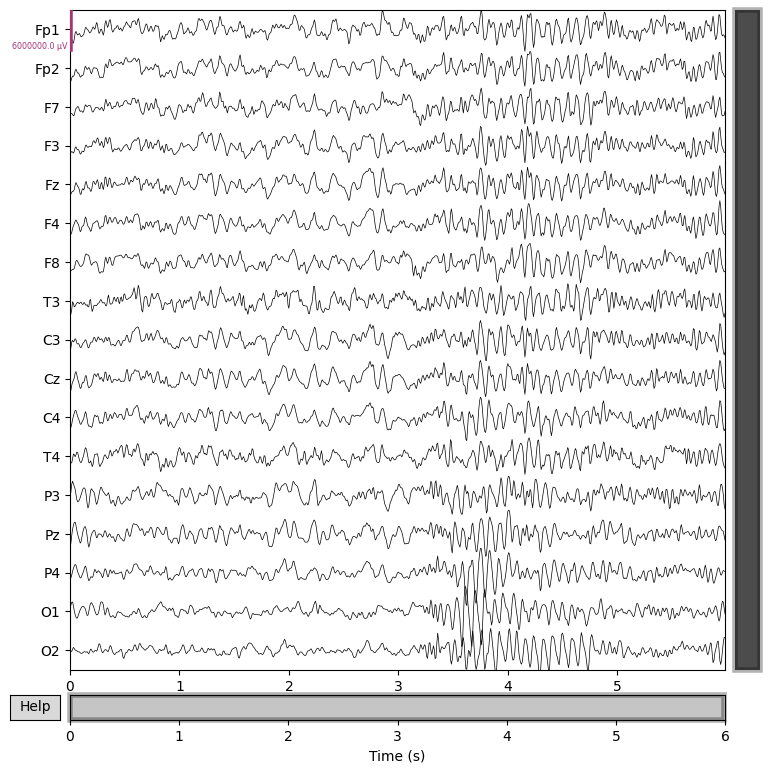

In [13]:
g = plot_one_window(one_window_zscored, scalings = dict(eeg=3))

For my application it is save to set common order to 9 (we are aiming at around 5 frequency peaks) (this is shown in another notebook by sampling the dataset to probe for PSDs and AIC criterion). Considering the set length of the epoch to 6 x 128 the unbiased version of the algorithm can be safely used (iwhat = 2).

## input: one epoch

### standard approach

In [14]:
AR, _ = AR_coeff(one_window_zscored)
mvar_H = mvar_H(AR)

### prepare band-averaged features of non-normalized DTF (magnitude) & frequency normalized DTF

In [15]:
NDTF = np.abs(mvar_H) ** 2 #not normalized
ffDTF = ffDTF(mvar_H)

## visualization for one directed information flow

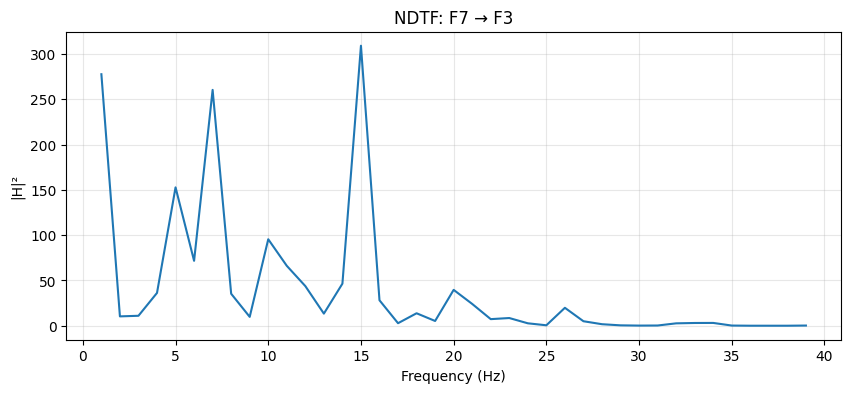

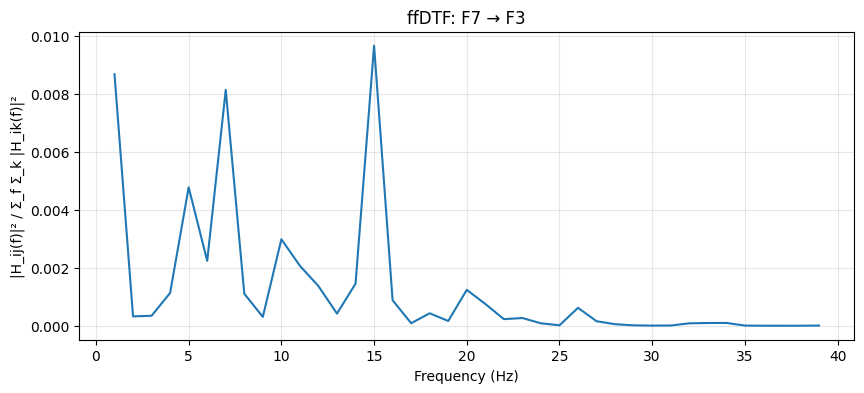

In [16]:
plot_one_flow(NDTF, 2, 3, ylabel = "|H|²", conn_name = 'NDTF')
plot_one_flow(ffDTF, 2, 3)

It looks as predicted -> very similar with other values on y axis.

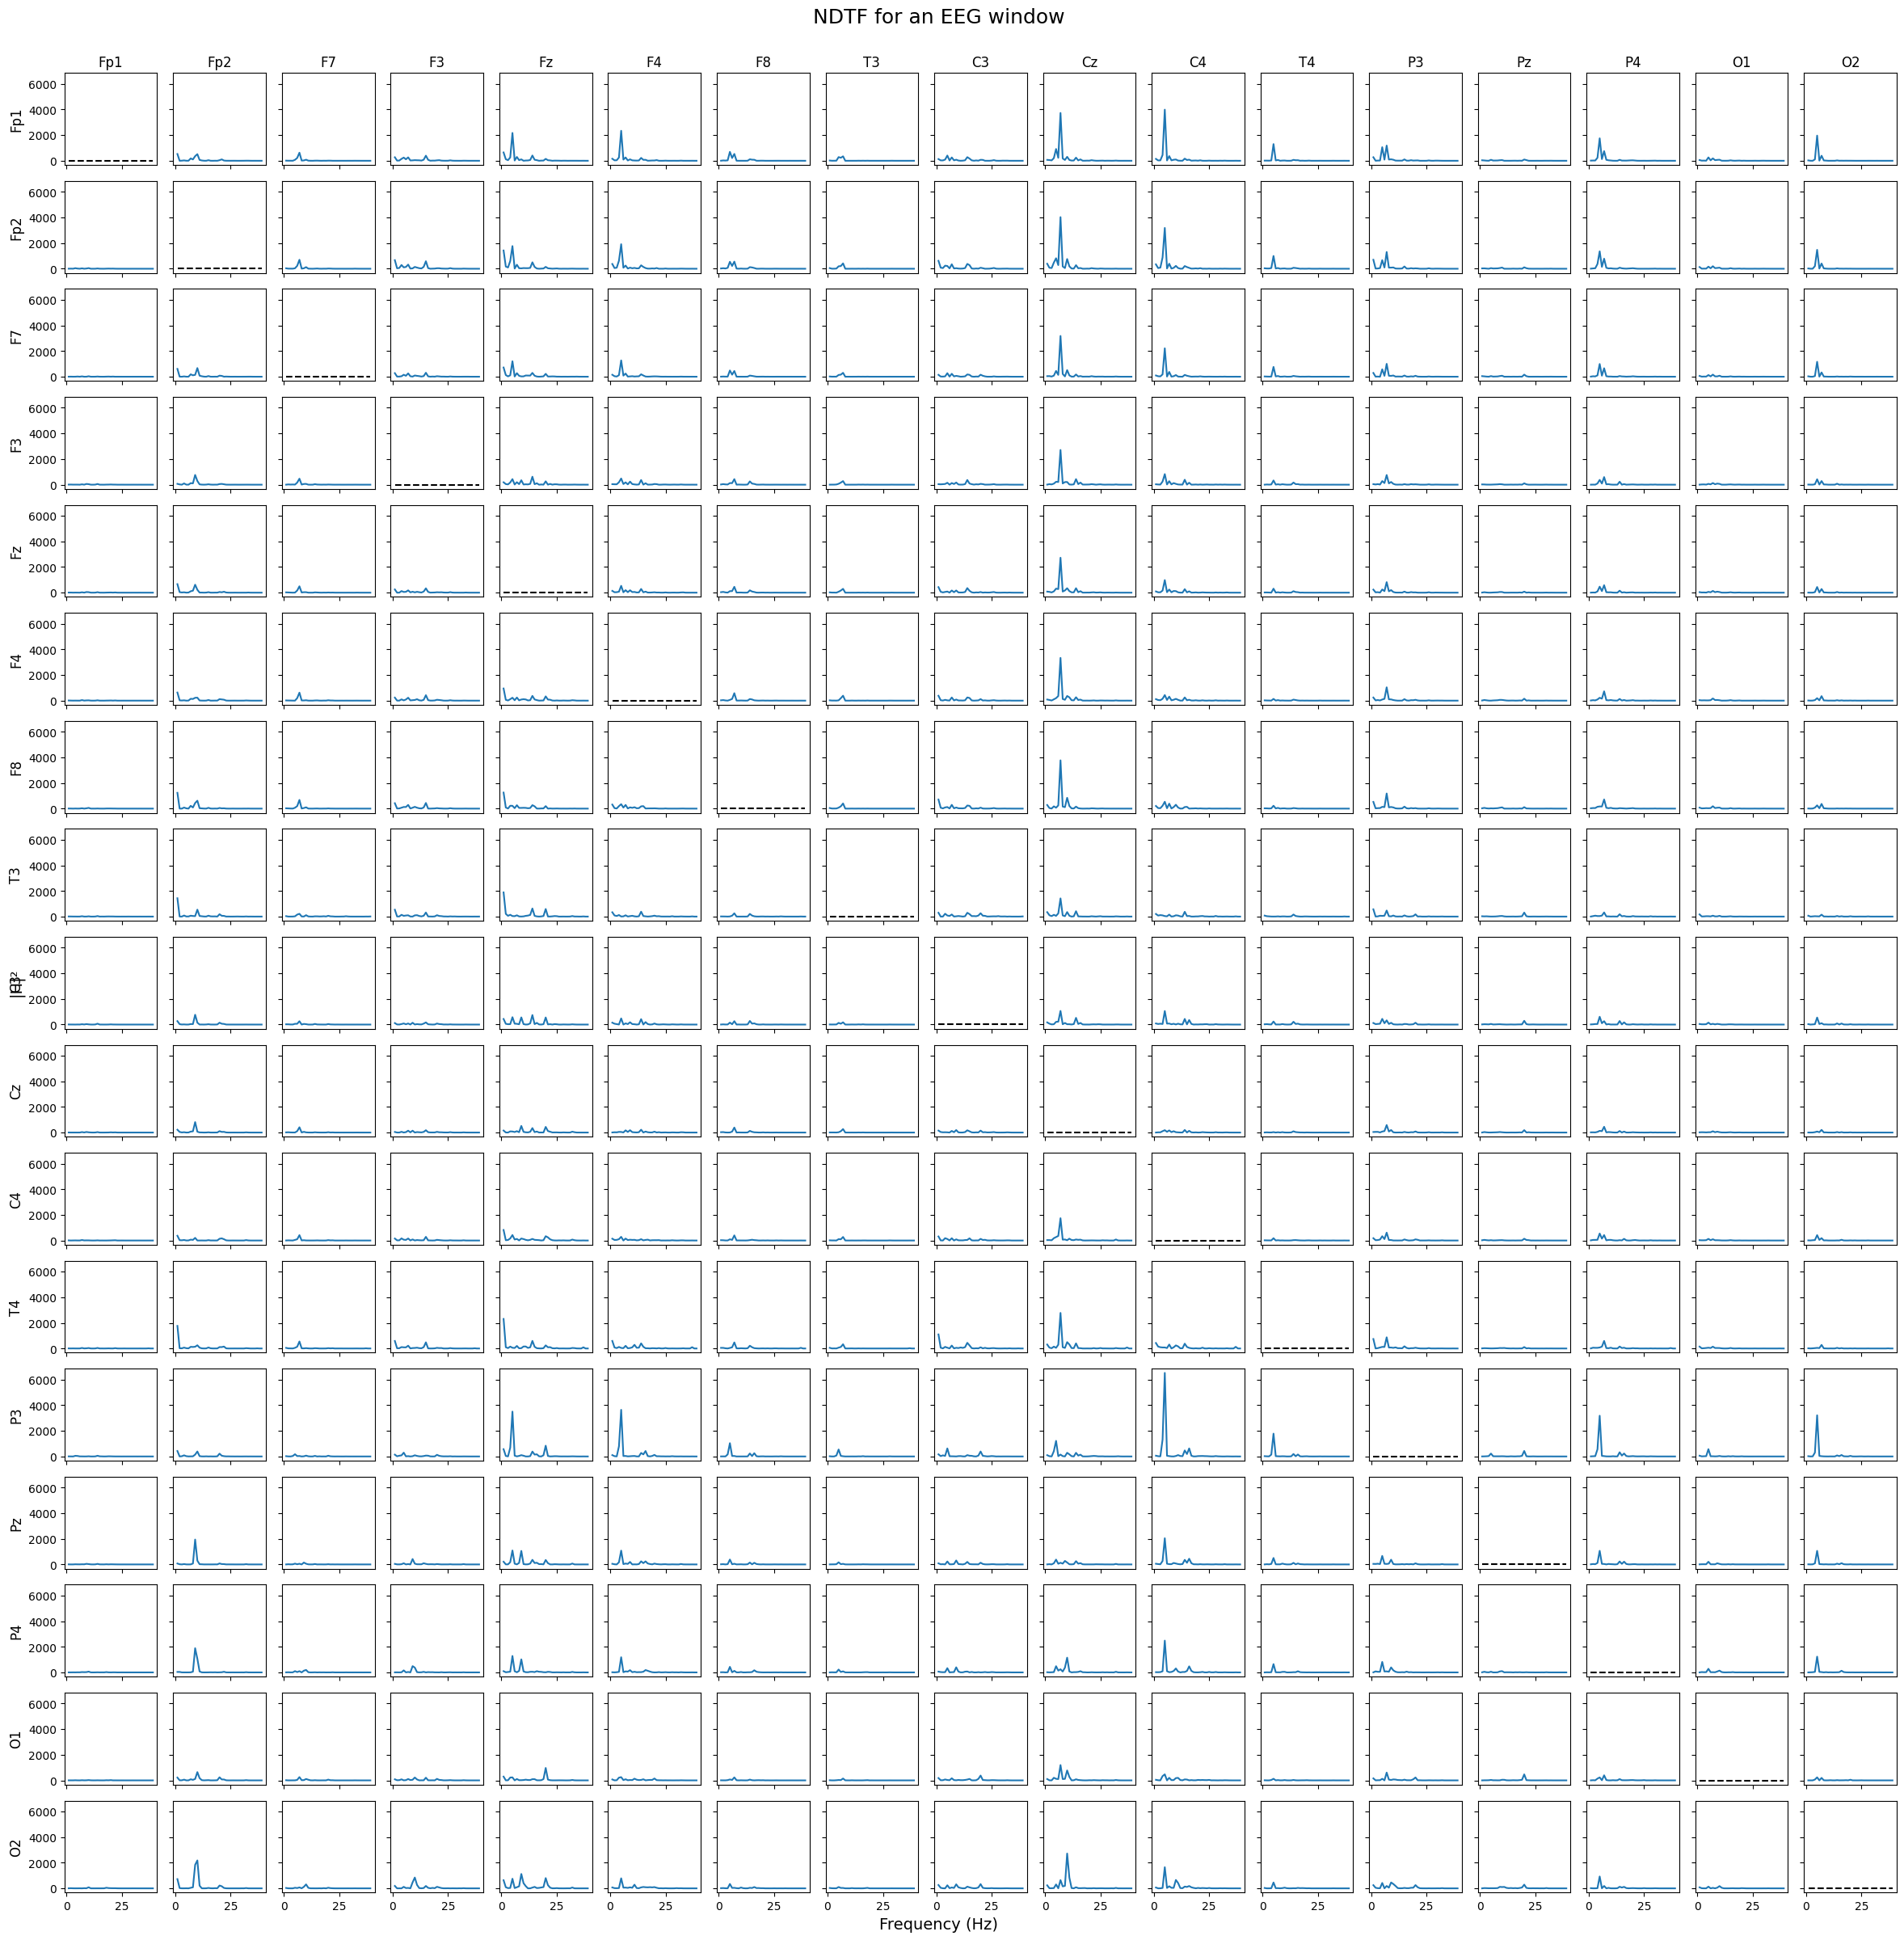

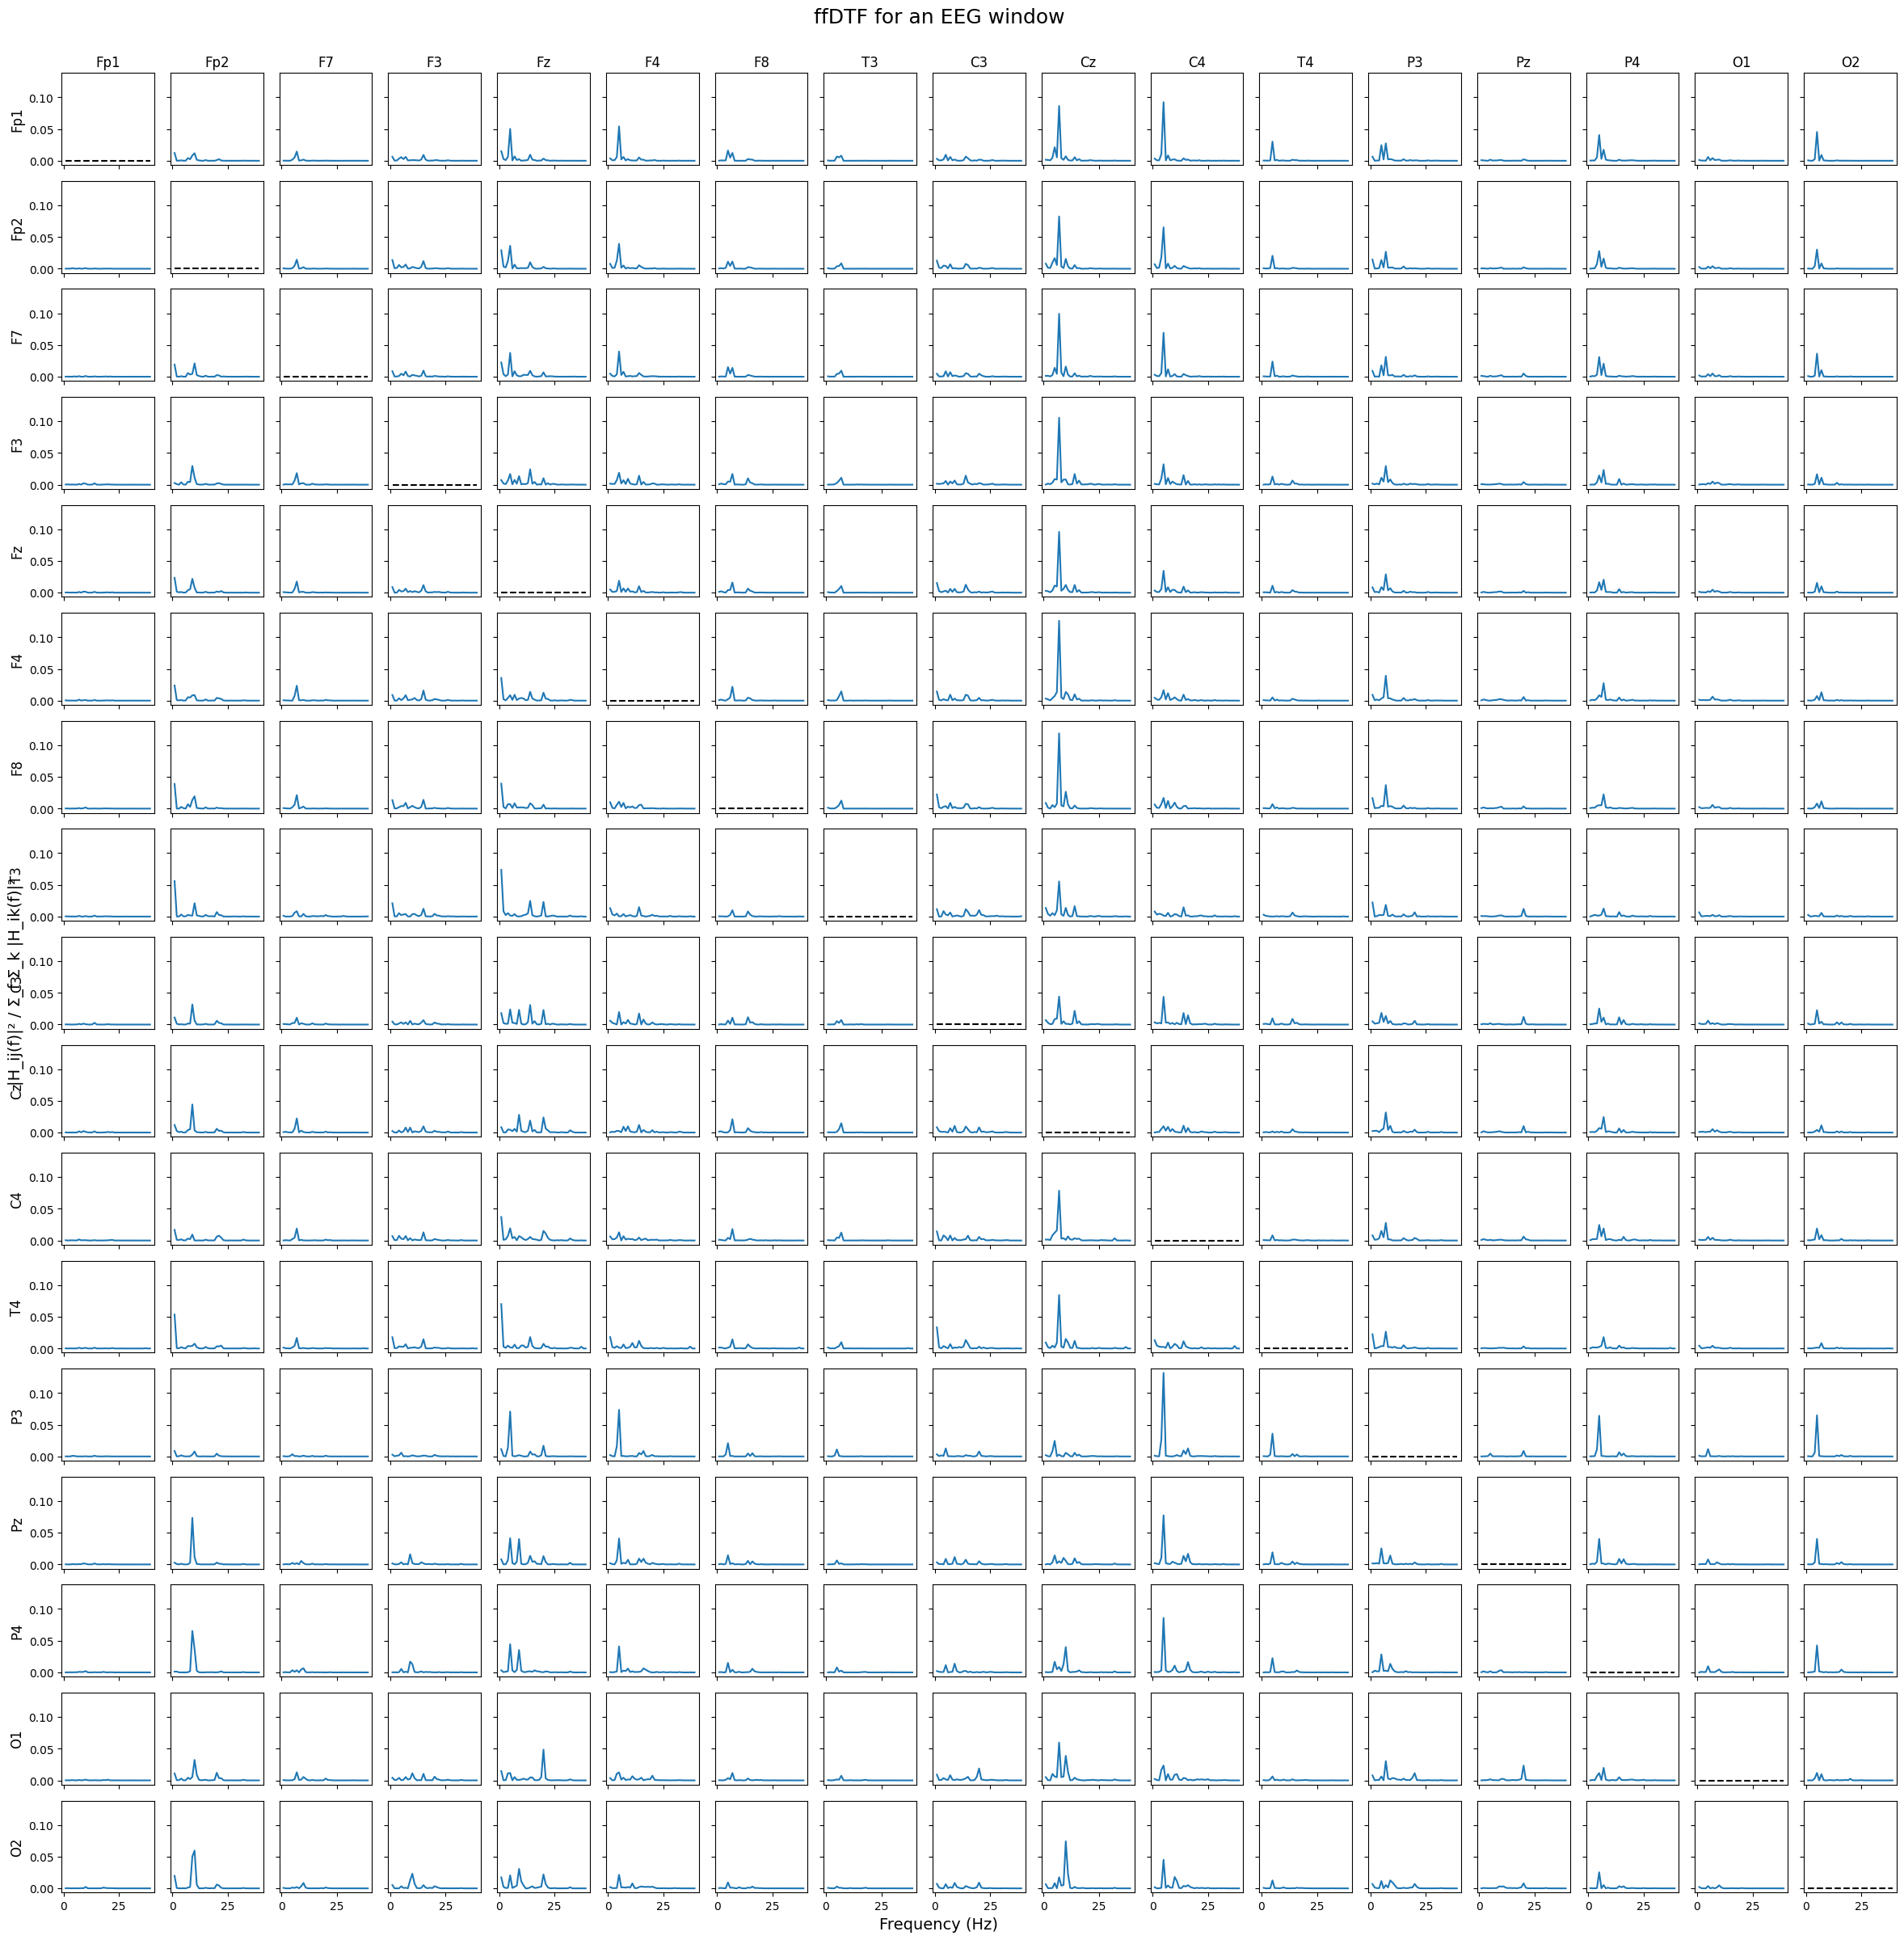

In [17]:
plot_all_flows(NDTF, ylabel = "|H|²", conn_name = 'NDTF')
plot_all_flows(ffDTF) #ylabel and name are set default to ffDTF

## create connectivity matrices aggregated over frequency bands

Use ordering invariant aggregation (sum by default, mean can also be used).

In [23]:
NDTF_bands = aggregate_bands(NDTF, pool = np.sum) #or np.mean
ffDTF_bands = aggregate_bands(ffDTF) #pool is sum by default

## visualize connectivity by bands

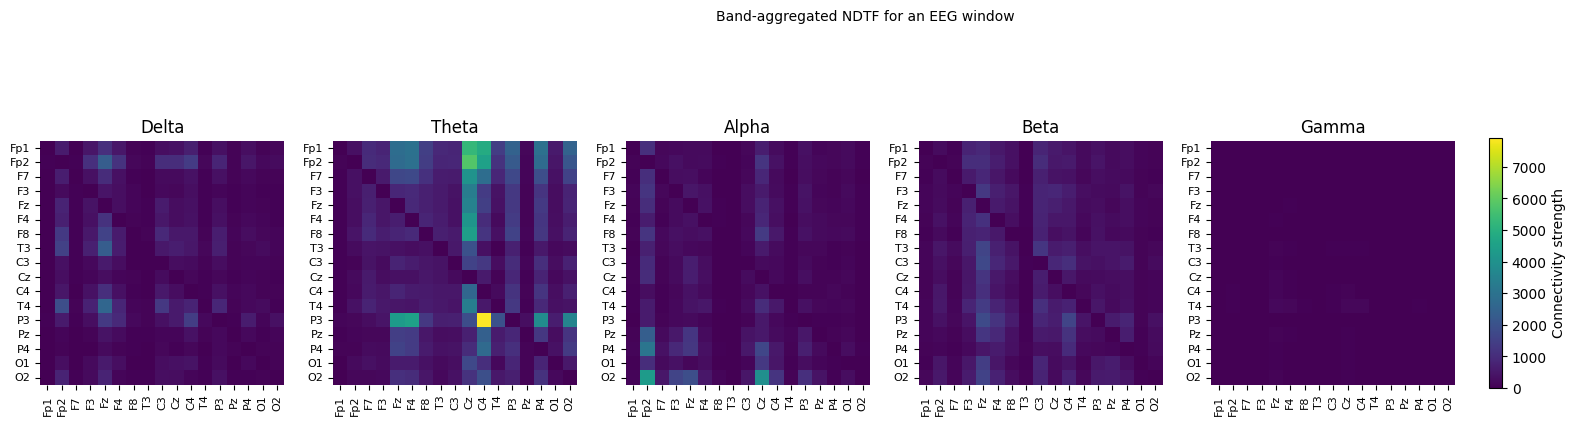

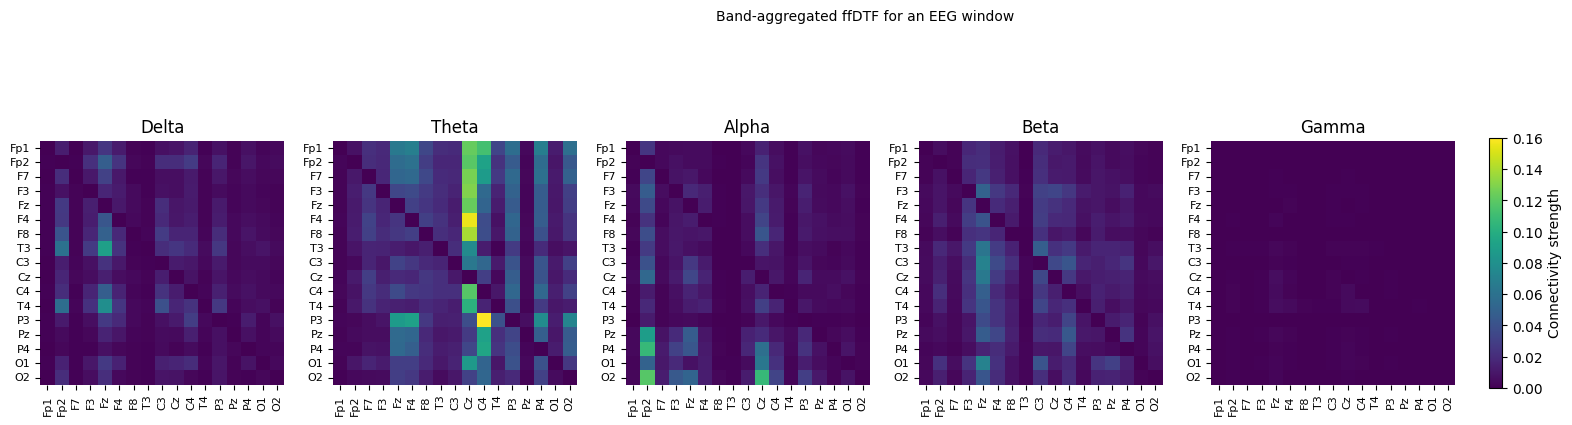

In [24]:
heatmap_bands(NDTF_bands, conn_name = 'NDTF')
heatmap_bands(ffDTF_bands)
plt.show()

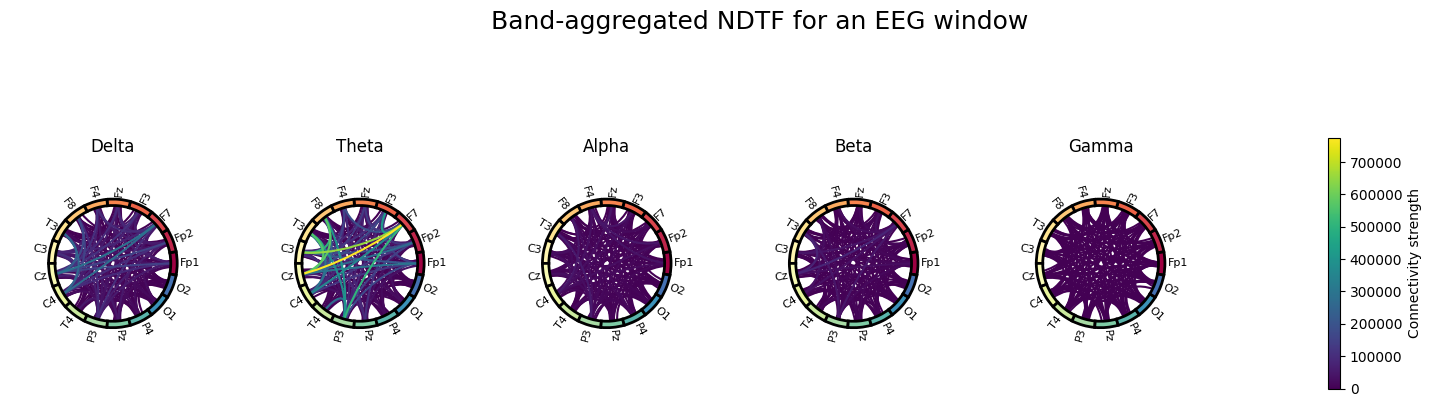

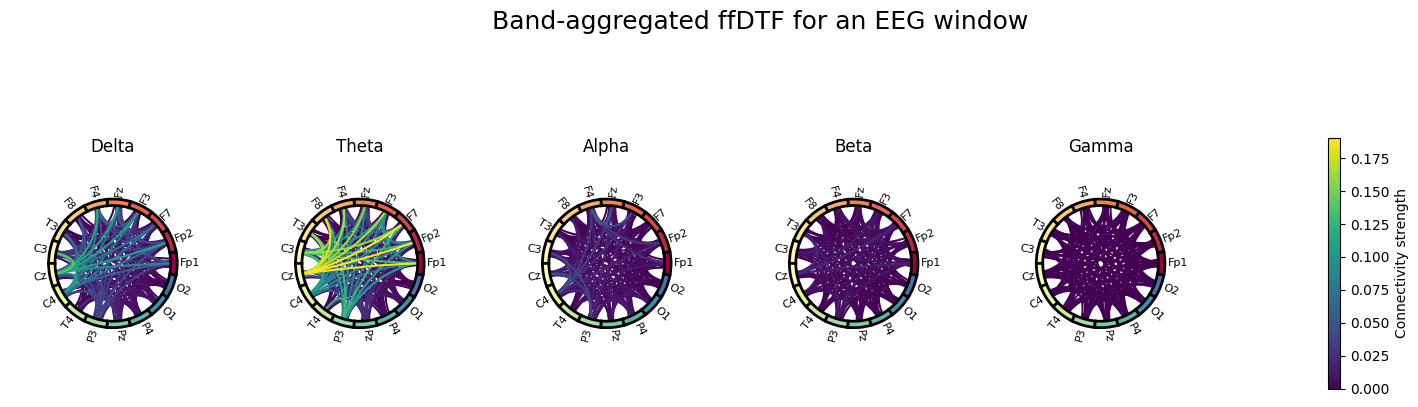

In [71]:
circle_bands(NDTF_bands, conn_name = 'NDTF')
circle_bands(ffDTF_bands)
plt.show()

## bands & graphs (visualize & create) with montage

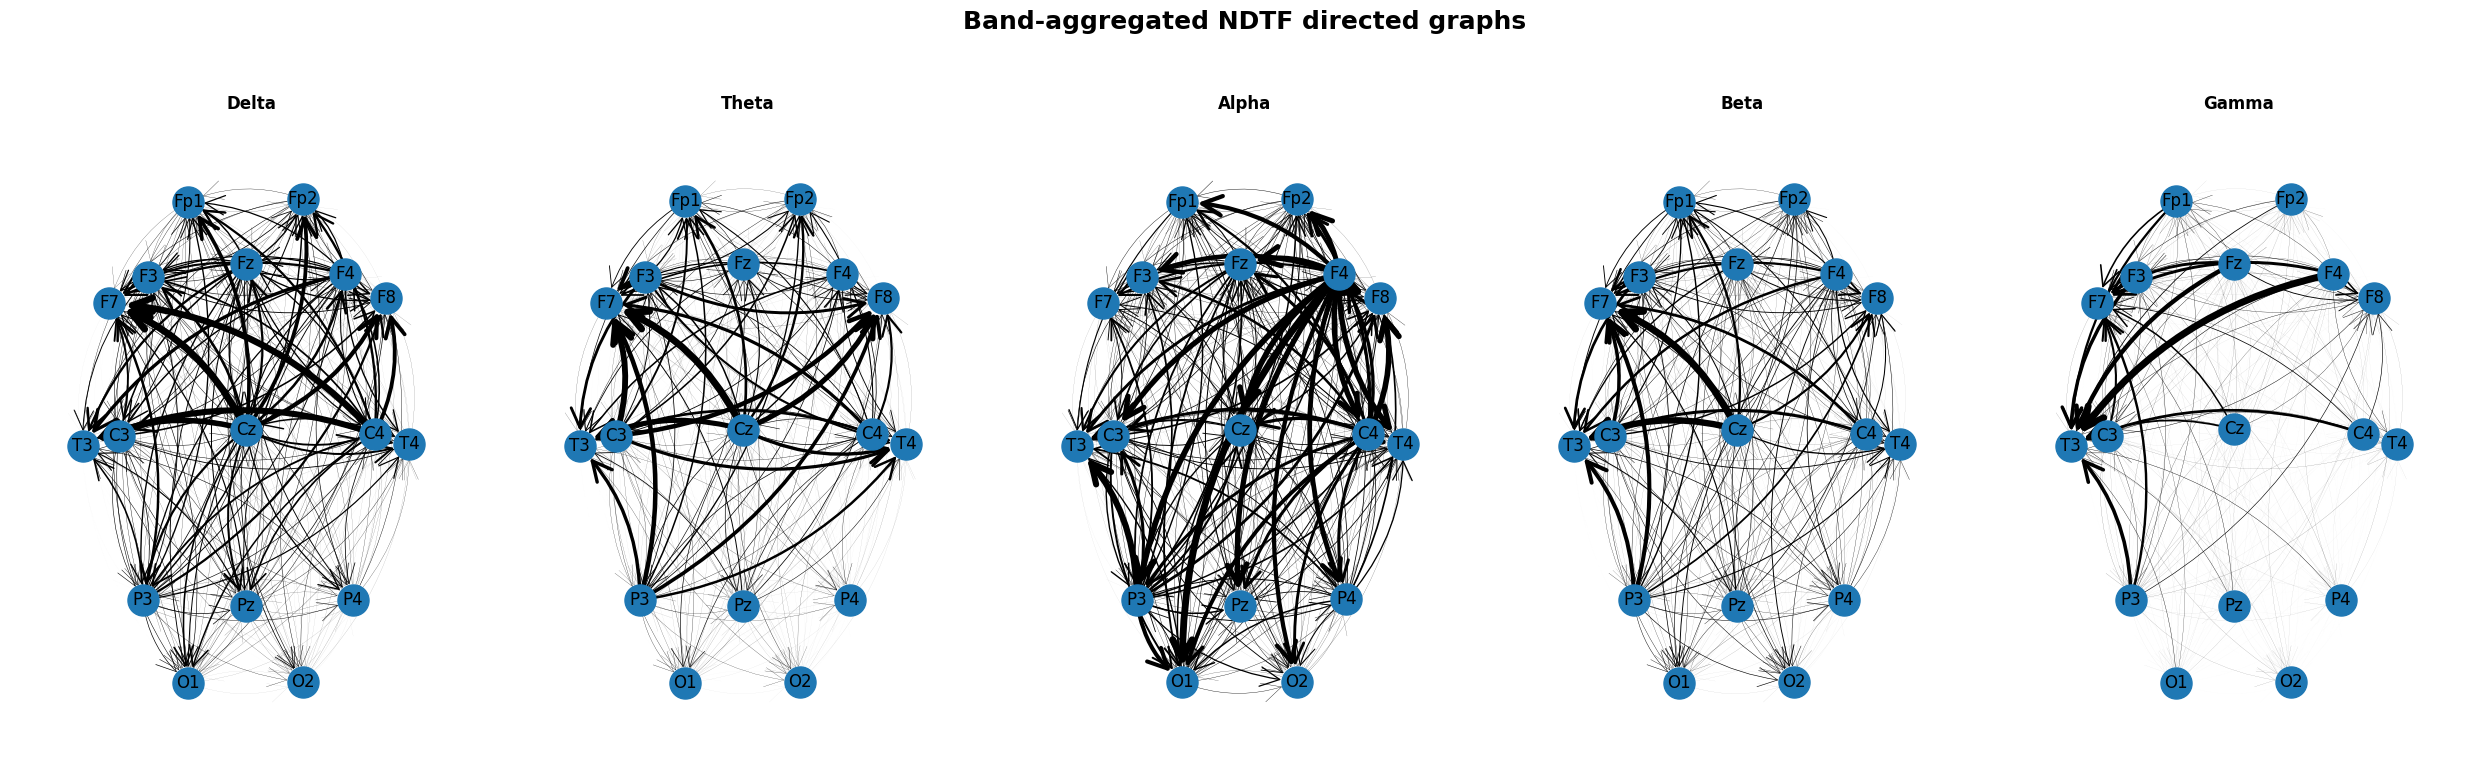

In [72]:
Gs_NDTF = graph_bands(NDTF_bands, conn_name = 'NDTF')
plt.show()

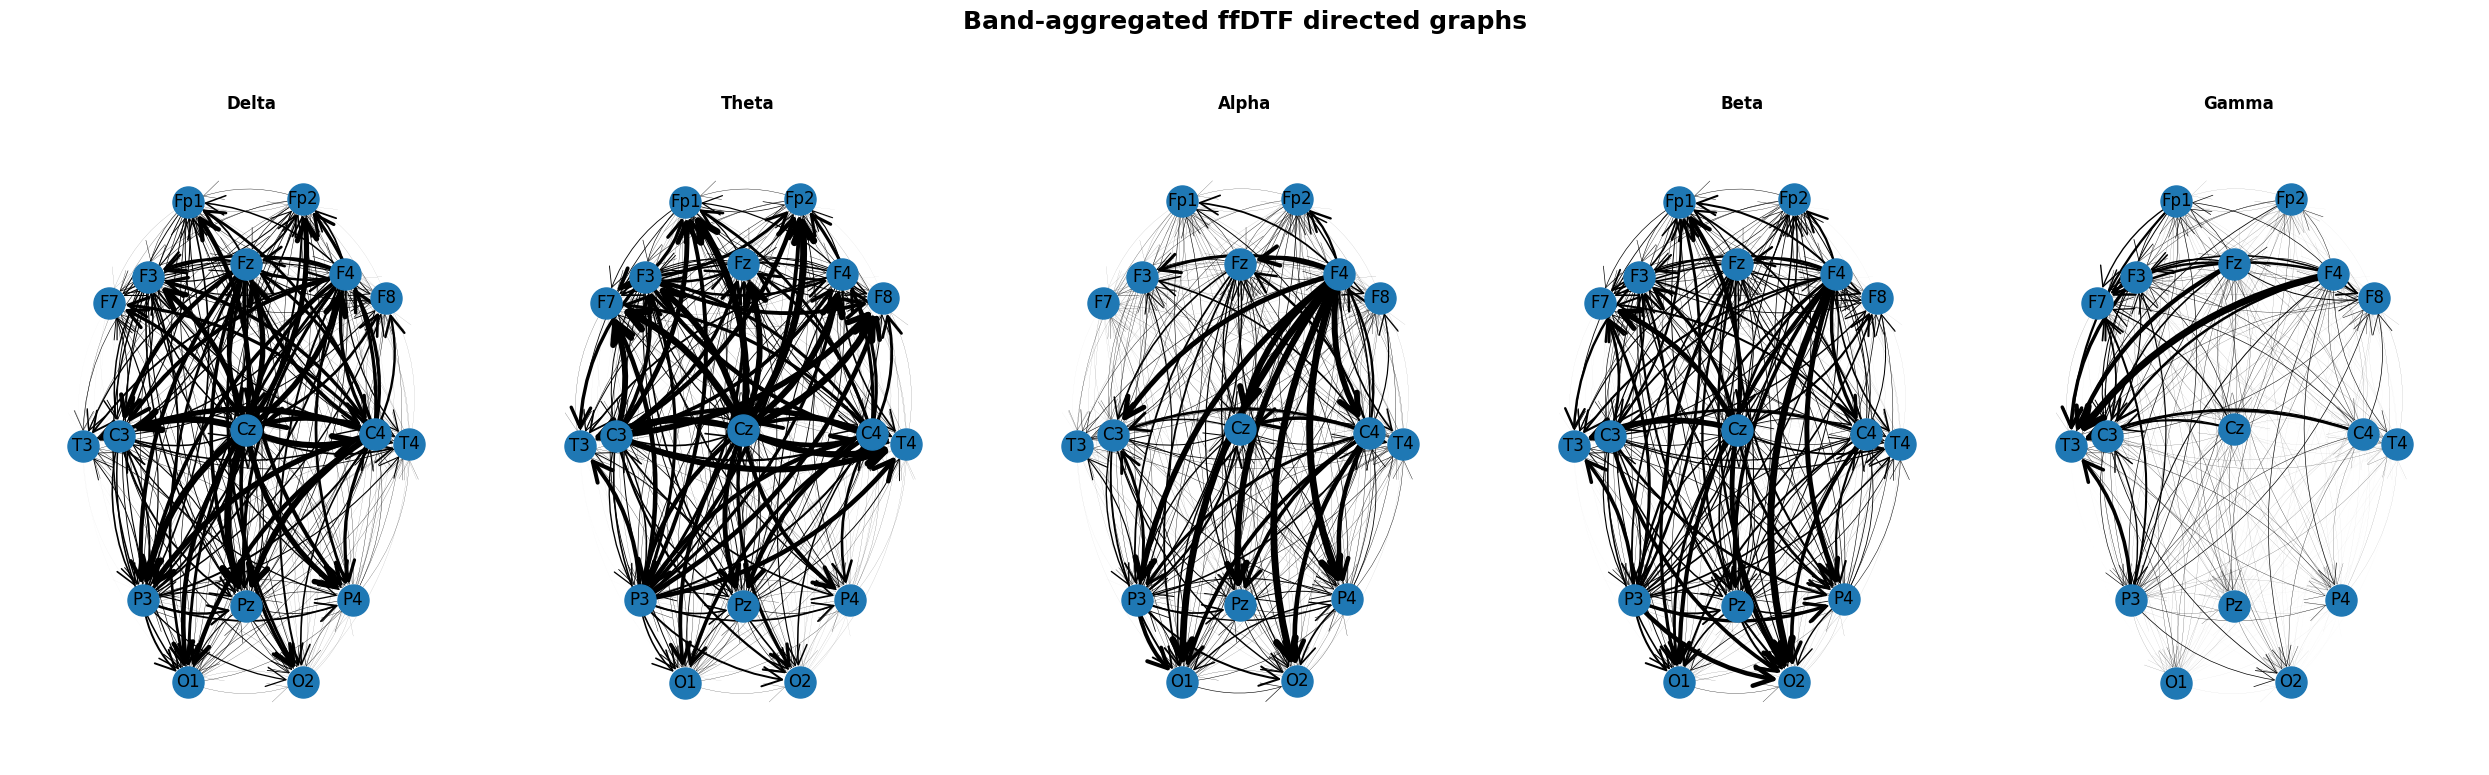

In [73]:
Gs_ffDTF = graph_bands(ffDTF_bands)
plt.show()

In [74]:
Gs_ffDTF_GA_metrics = compute_metrics_all(Gs_ffDTF)
# Gs_ffDTF is a dict of nx.DiGraphs with band-names as keys
#GT = Gs_ffDTF['theta'], then the single graph metrics can be computed as compute_graph_metrics(GT)

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/networkx/algorithms/assortativity/correlation.py:302: RuntimeWarning: invalid value encountered in scalar divide
  return float((xy * (M - ab)).sum() / np.sqrt(vara * varb))


In [75]:
GT = Gs_ffDTF['Theta']
m = compute_graph_metrics(GT)
m

{'density': 1.0,
 'transitivity': 1.0,
 'average_clustering': 0.12985627510875922,
 'global_efficiency': 1.0,
 'local_efficiency': 1.0,
 'average_path_length': 1.0,
 'degree_assortativity': nan,
 'small_world_sigma': np.float64(0.1409891544777186),
 'degree_centrality': {0: 1.0,
  1: 1.0,
  2: 1.0,
  3: 1.0,
  4: 1.0,
  5: 1.0,
  6: 1.0,
  7: 1.0,
  8: 1.0,
  9: 1.0,
  10: 1.0,
  11: 1.0,
  12: 1.0,
  13: 1.0,
  14: 1.0,
  15: 1.0,
  16: 1.0},
 'betweenness_centrality': {0: 0.0,
  1: 0.0,
  2: 0.0,
  3: 0.0,
  4: 0.025,
  5: 0.2,
  6: 0.0,
  7: 0.325,
  8: 0.0,
  9: 0.0,
  10: 0.0,
  11: 0.0,
  12: 0.0,
  13: 0.0,
  14: 0.0,
  15: 0.0,
  16: 0.6583333333333333},
 'eigenvector_centrality': {0: 0.2521244834862906,
  1: 0.25006300821357536,
  2: 0.2799185705341673,
  3: 0.27212456009347663,
  4: 0.2125385192086955,
  5: 0.2248437981314317,
  6: 0.2242441512460628,
  7: 0.2032174793943051,
  8: 0.37841190243771305,
  9: 0.46627920898349734,
  10: 0.2901588065757848,
  11: 0.050061356906508

## graphs with only the strongest connections

Although the [EEGraph](https://github.com/ufvceiec/EEGRAPH/tree/feature/graph-metrics) package was not used, the thresholding/ top % convention and adding montagie position to graphs was inspired from it. Also, it enables to borrow compute_graph_metrics to compute metrics from classical Graph Analysis from each single graph (treting as undirected).

The default is set to take 10% strongest connections.

The global mode choosed top % of connections from all (in all bands), that's why the number of edges chosen varies across bands. Contrary, the per band mode choosed the top from band-local edges, thus all bands have equal number of chosen ones.

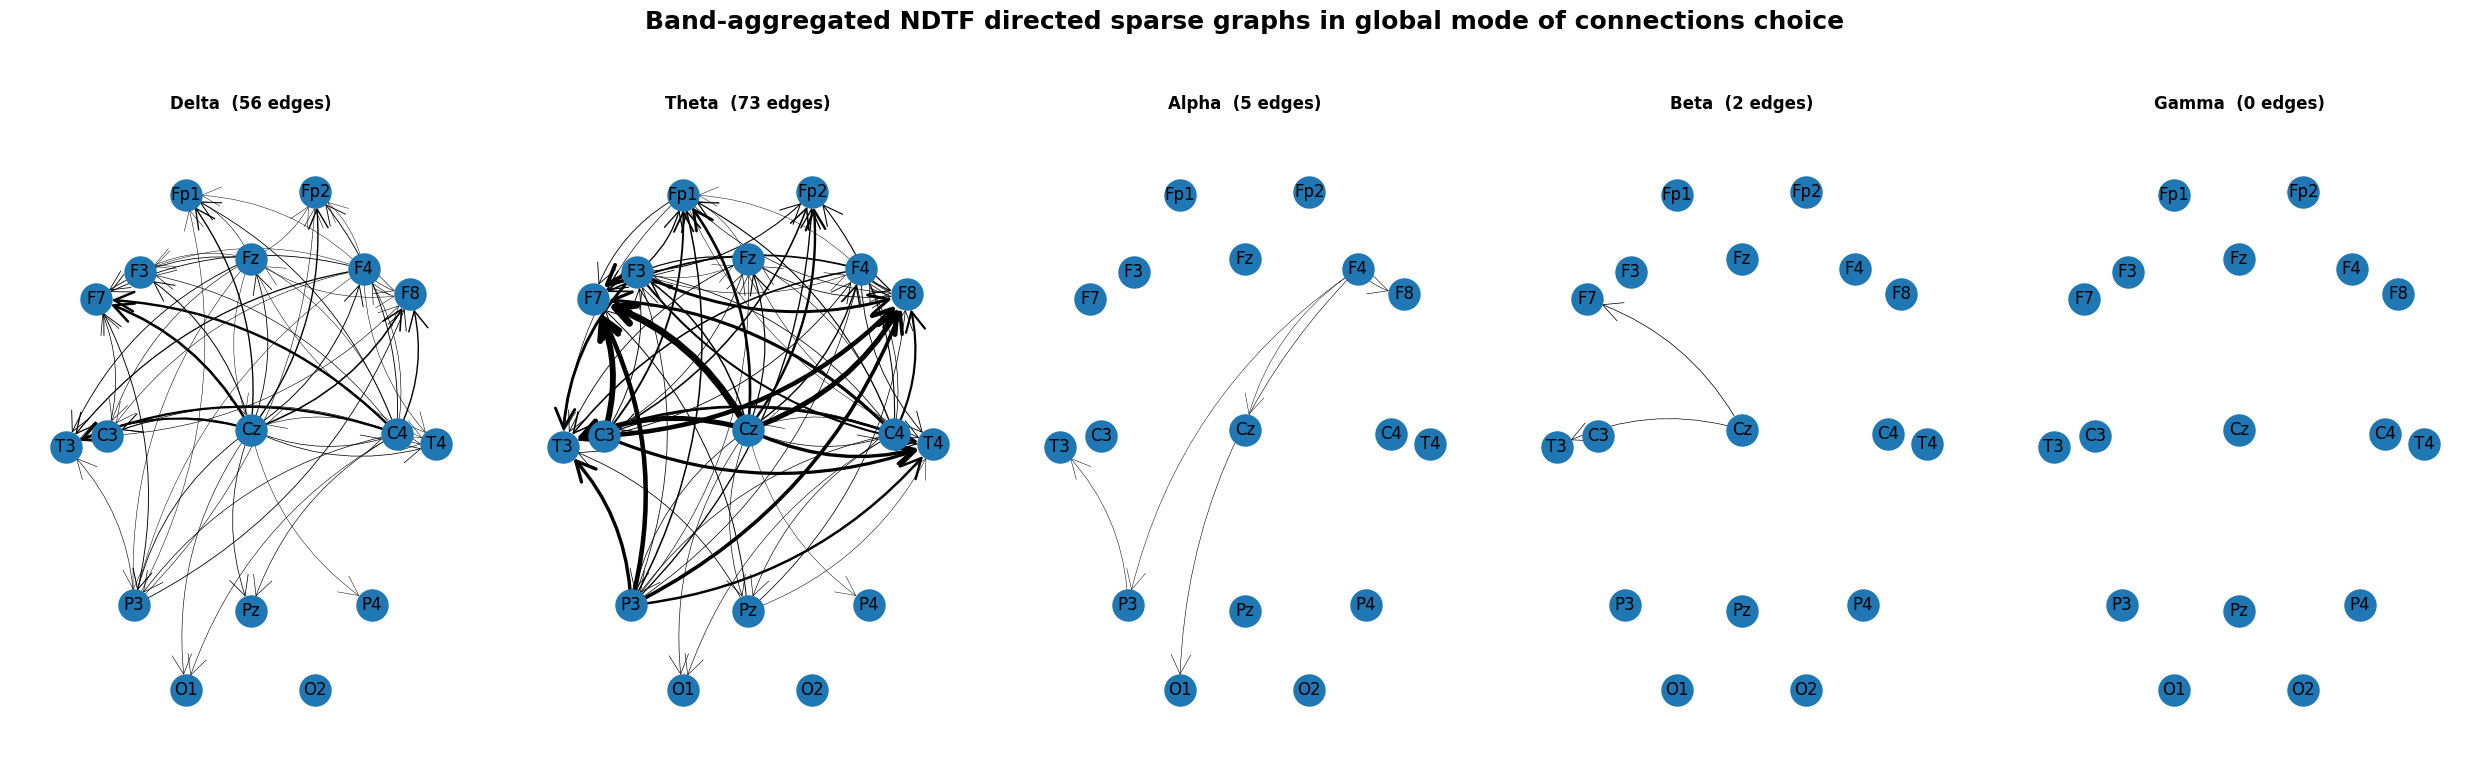

In [76]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'global', conn_name = 'NDTF')
plt.show()

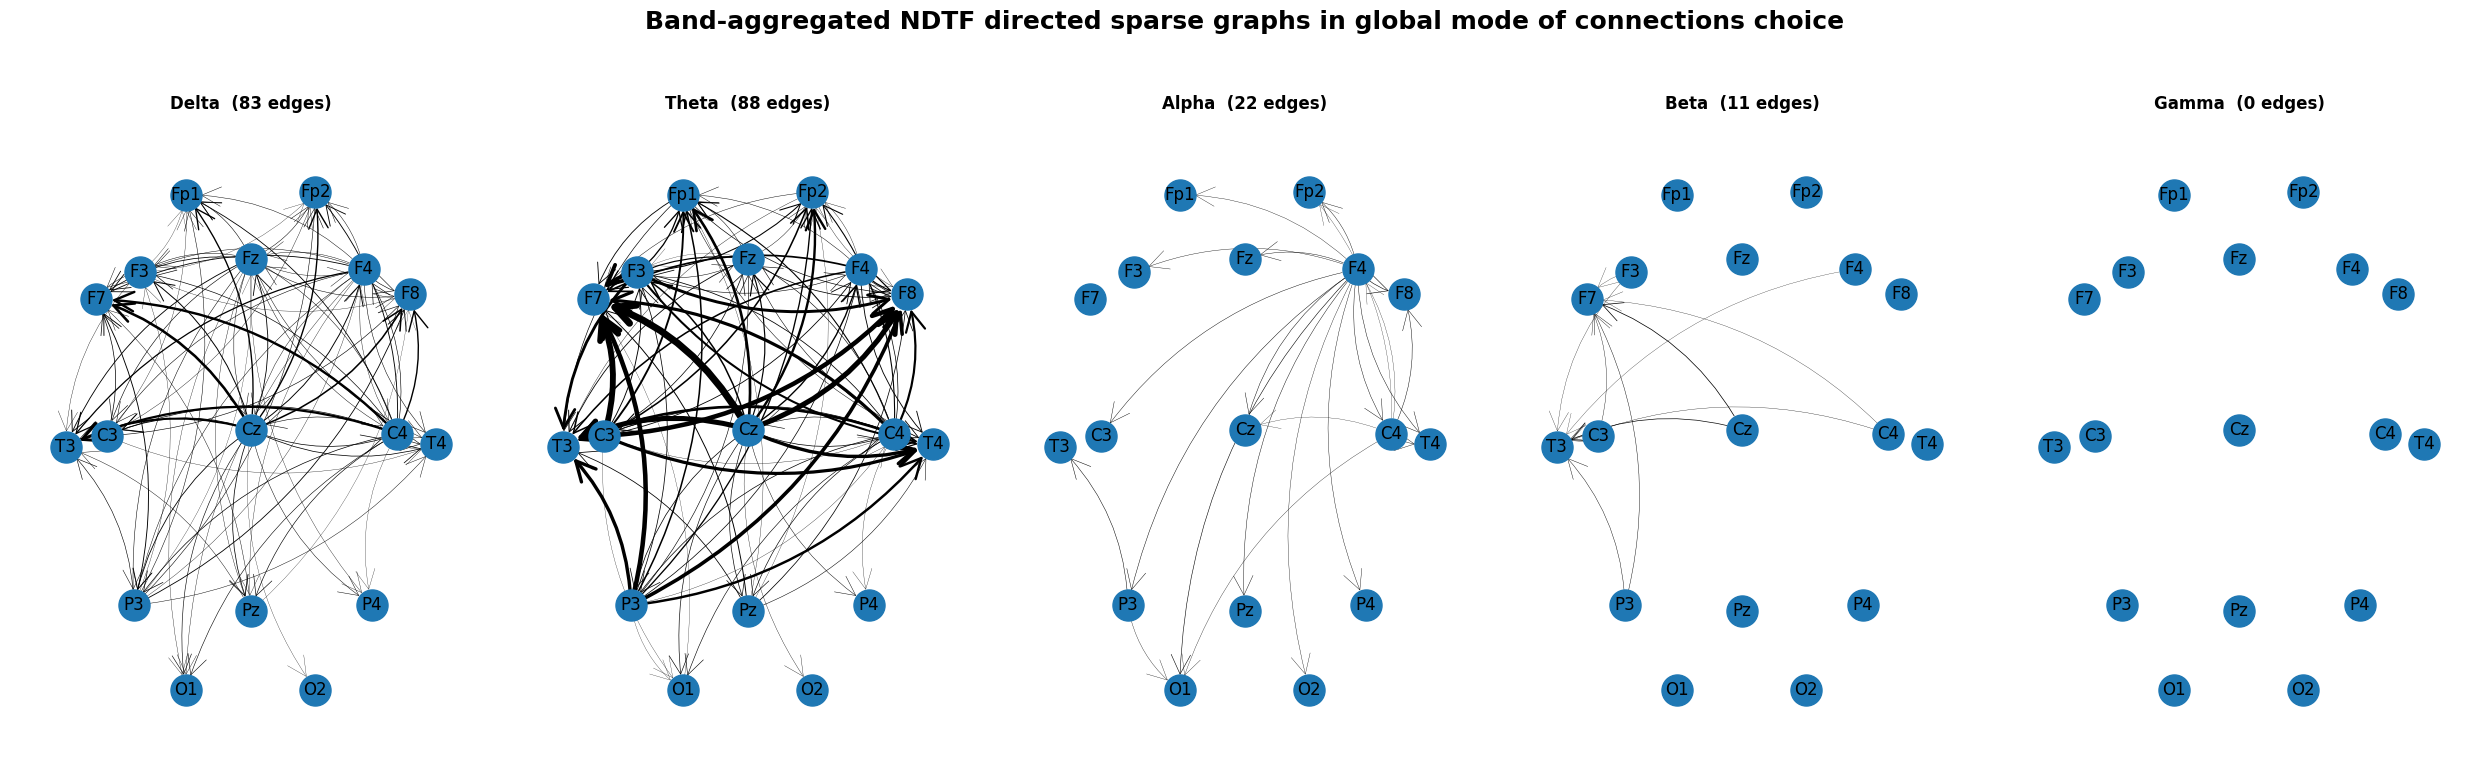

In [77]:
GsS_NDTF = graph_bands_sparse(NDTF_bands,top_percent = 15,  mode = 'global', conn_name = 'NDTF')
plt.show()

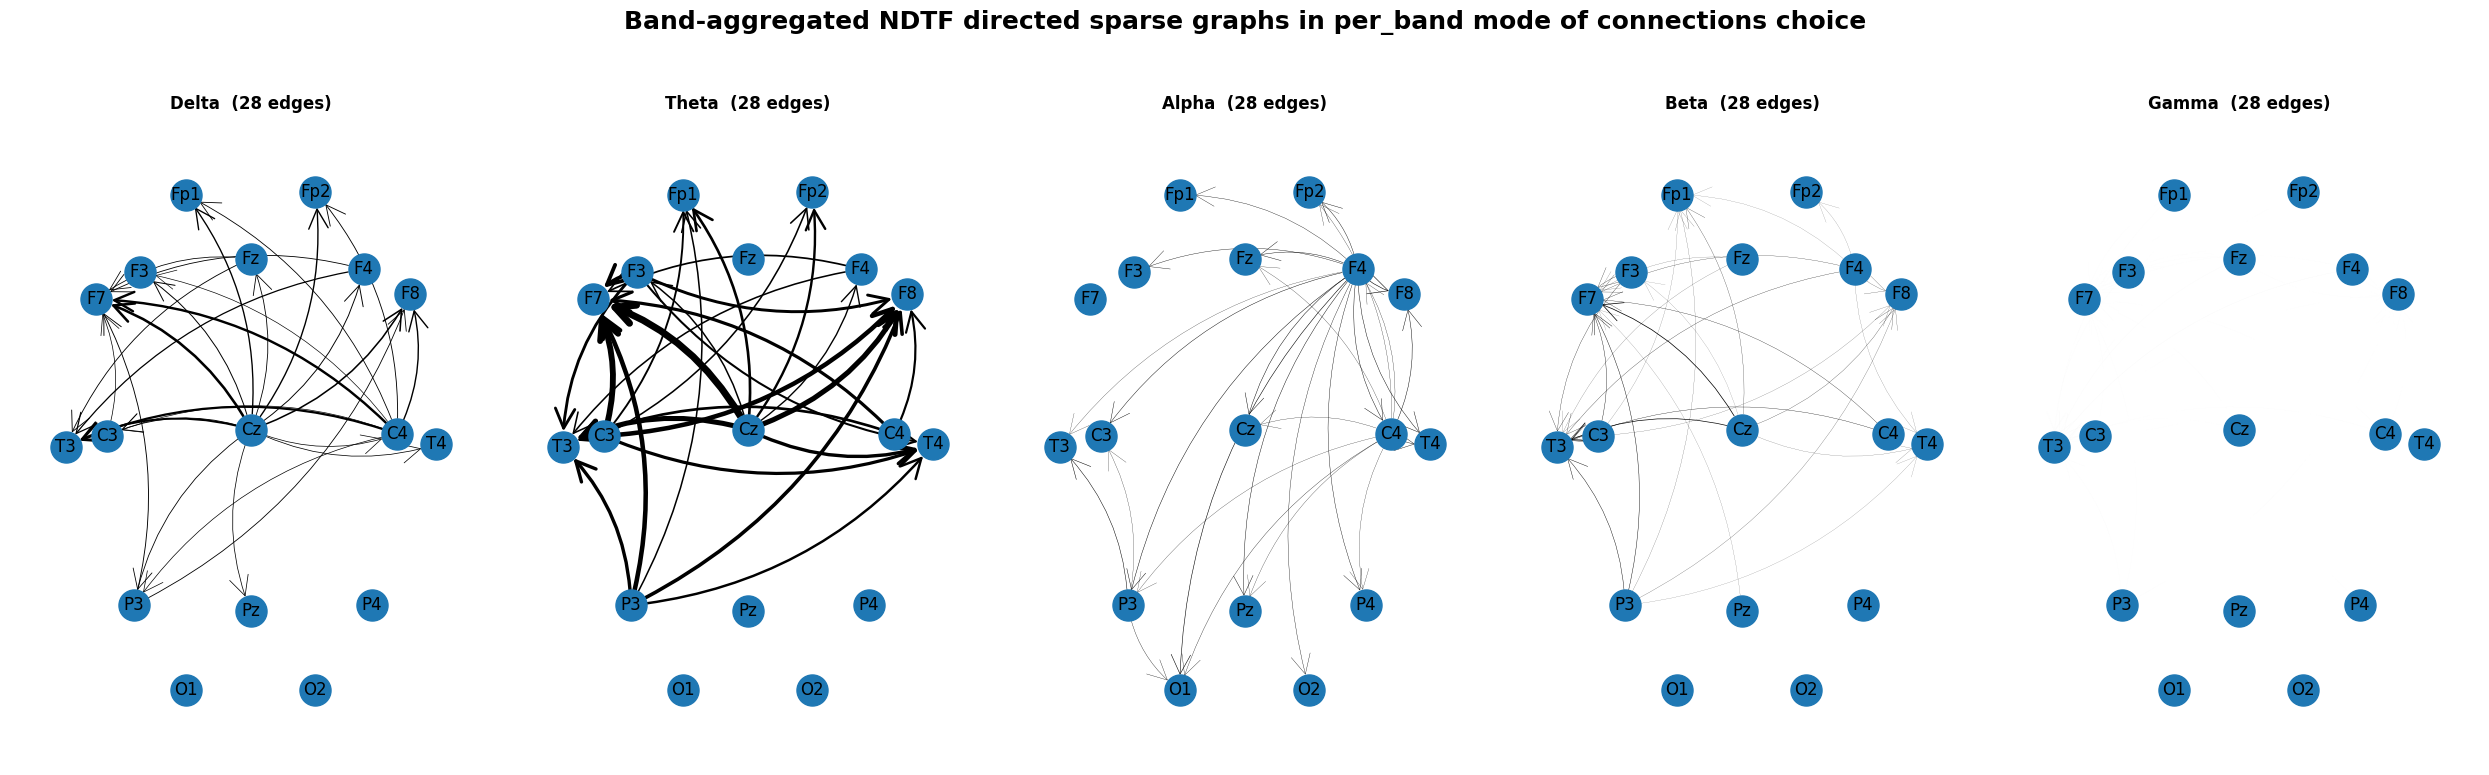

In [78]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'per_band', conn_name = 'NDTF')
plt.show()

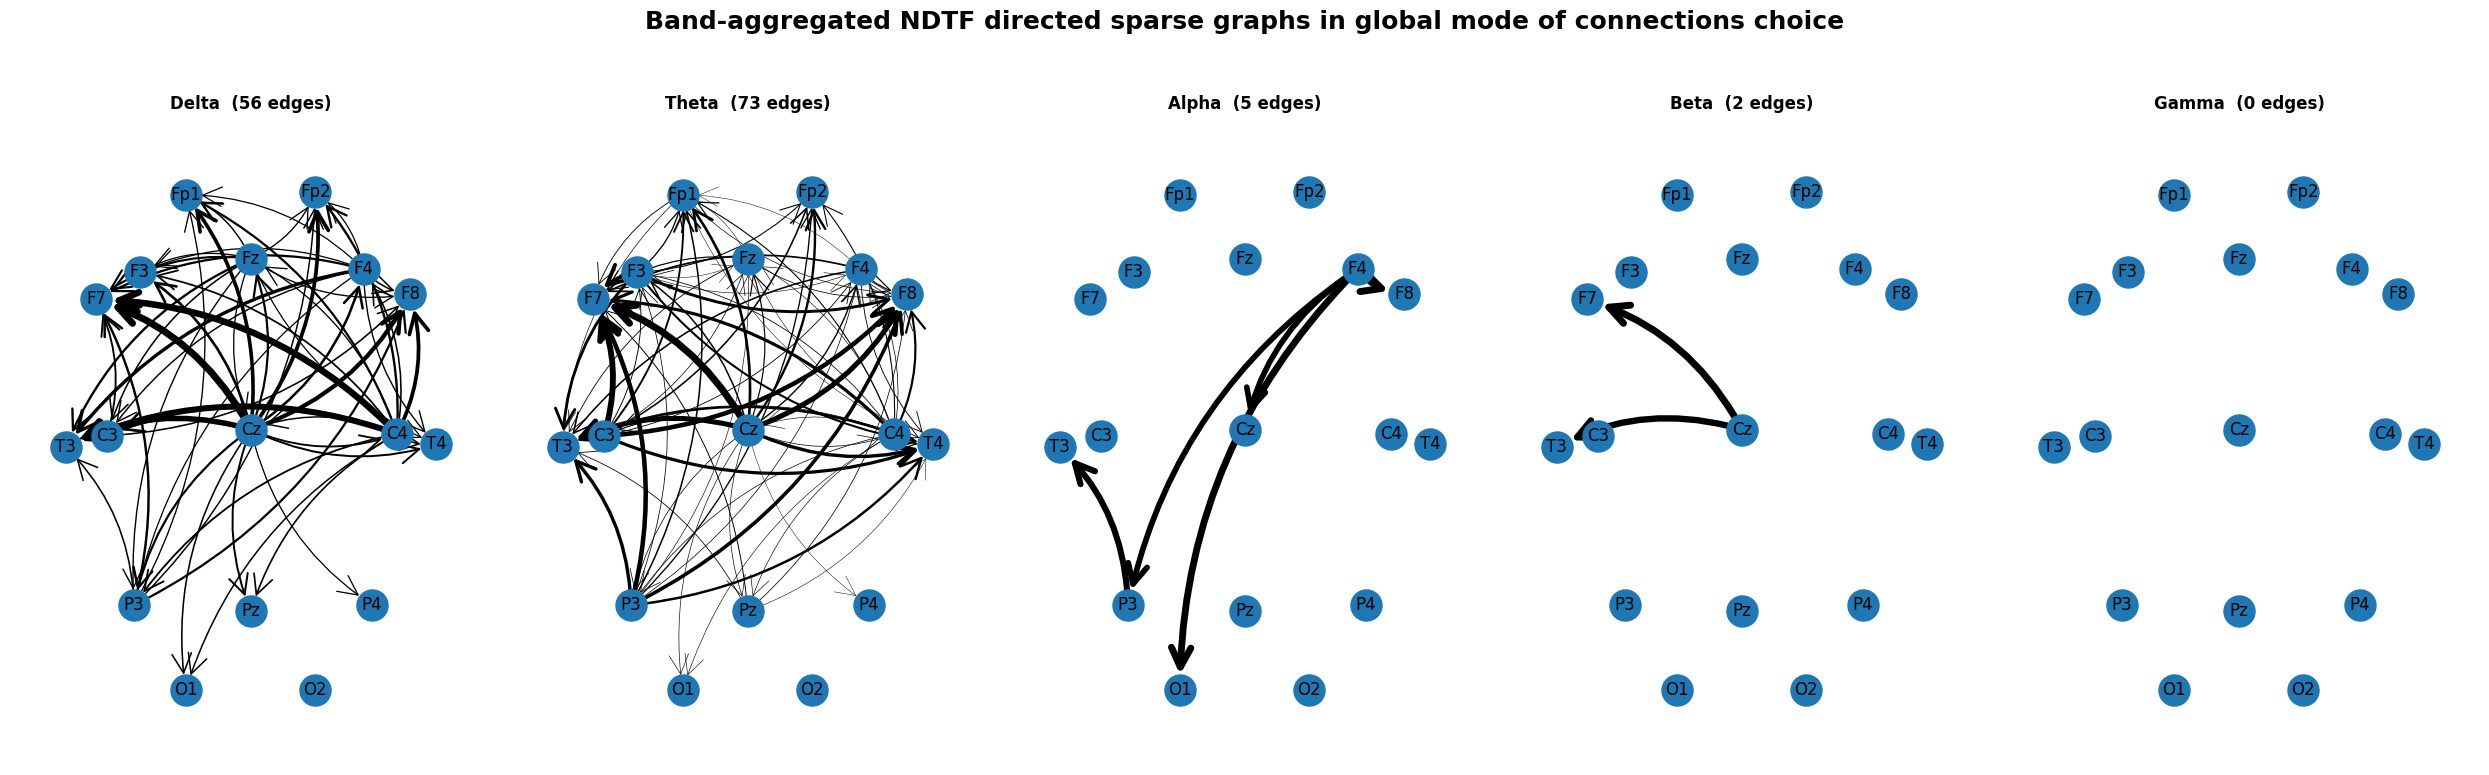

In [79]:
GsSB_NDTF = graph_bands_sparse(NDTF_bands, shared_scale = False, conn_name = 'NDTF')
plt.show()

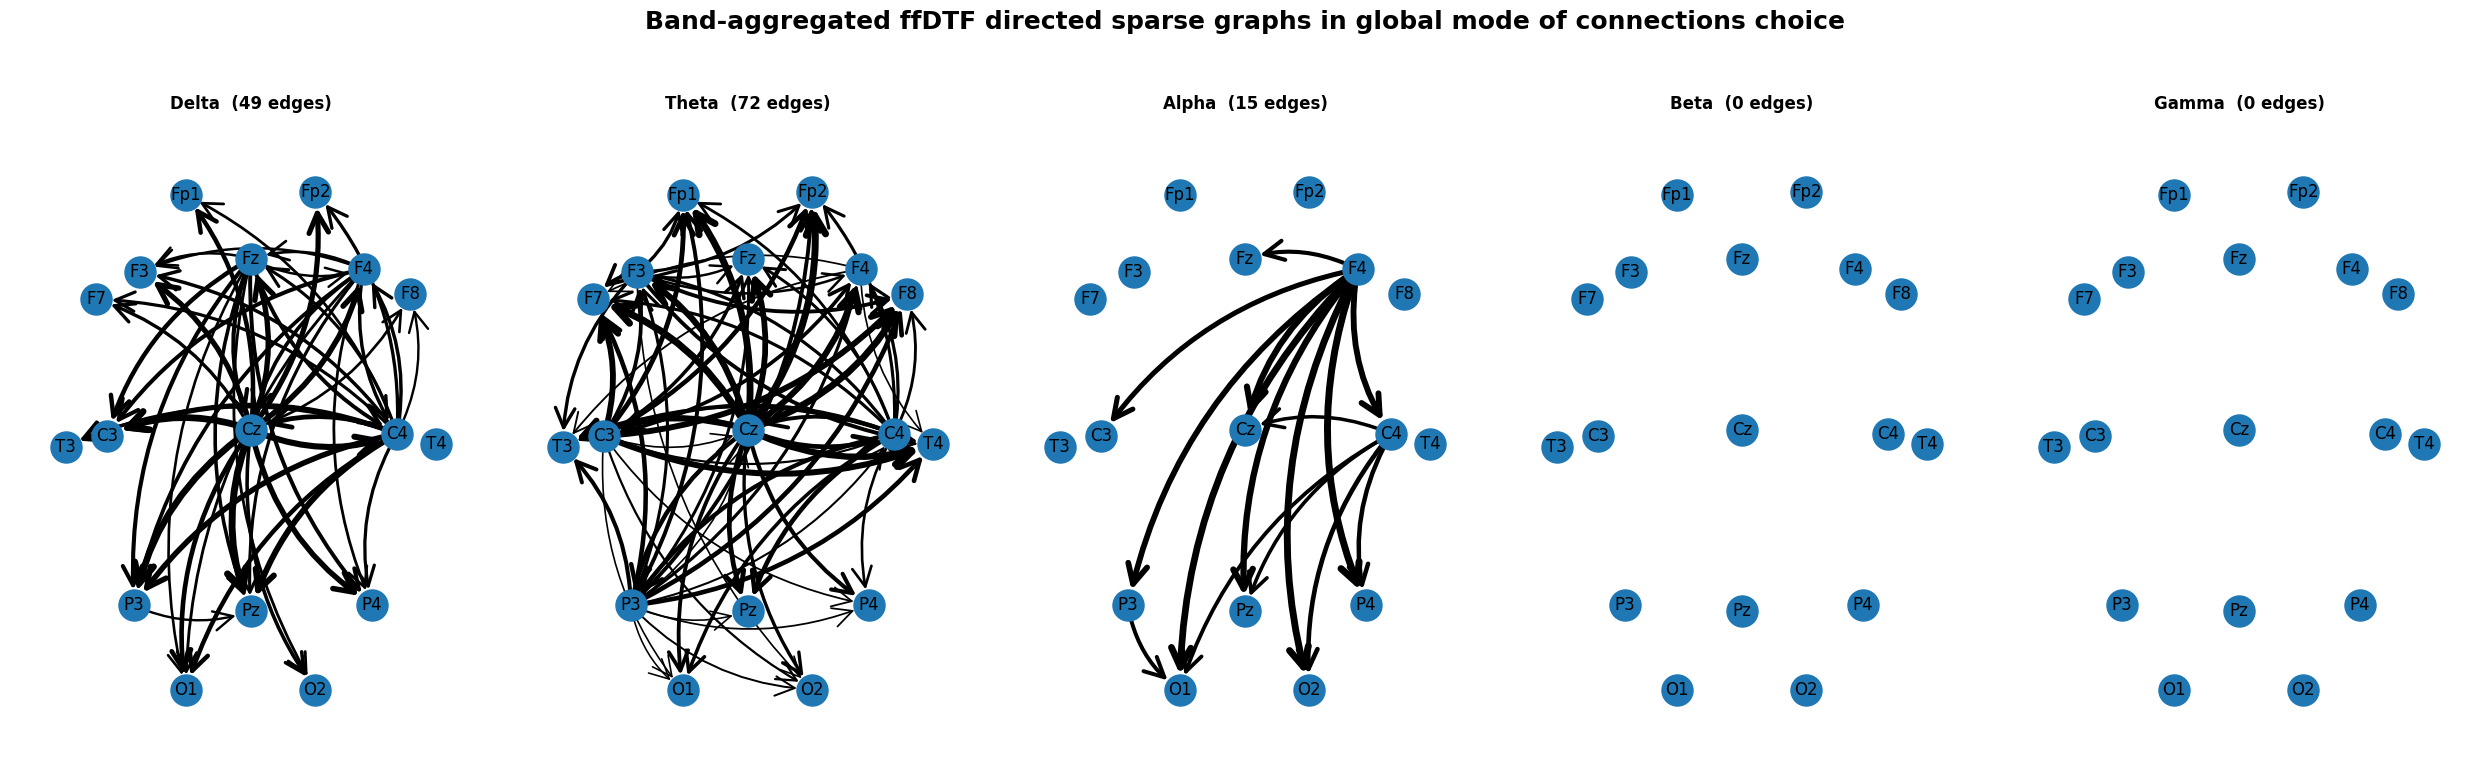

In [80]:
GsS_ffDTF = graph_bands_sparse(ffDTF_bands, shared_scale = False)
plt.show()

These two are the stringest candidates for graph features

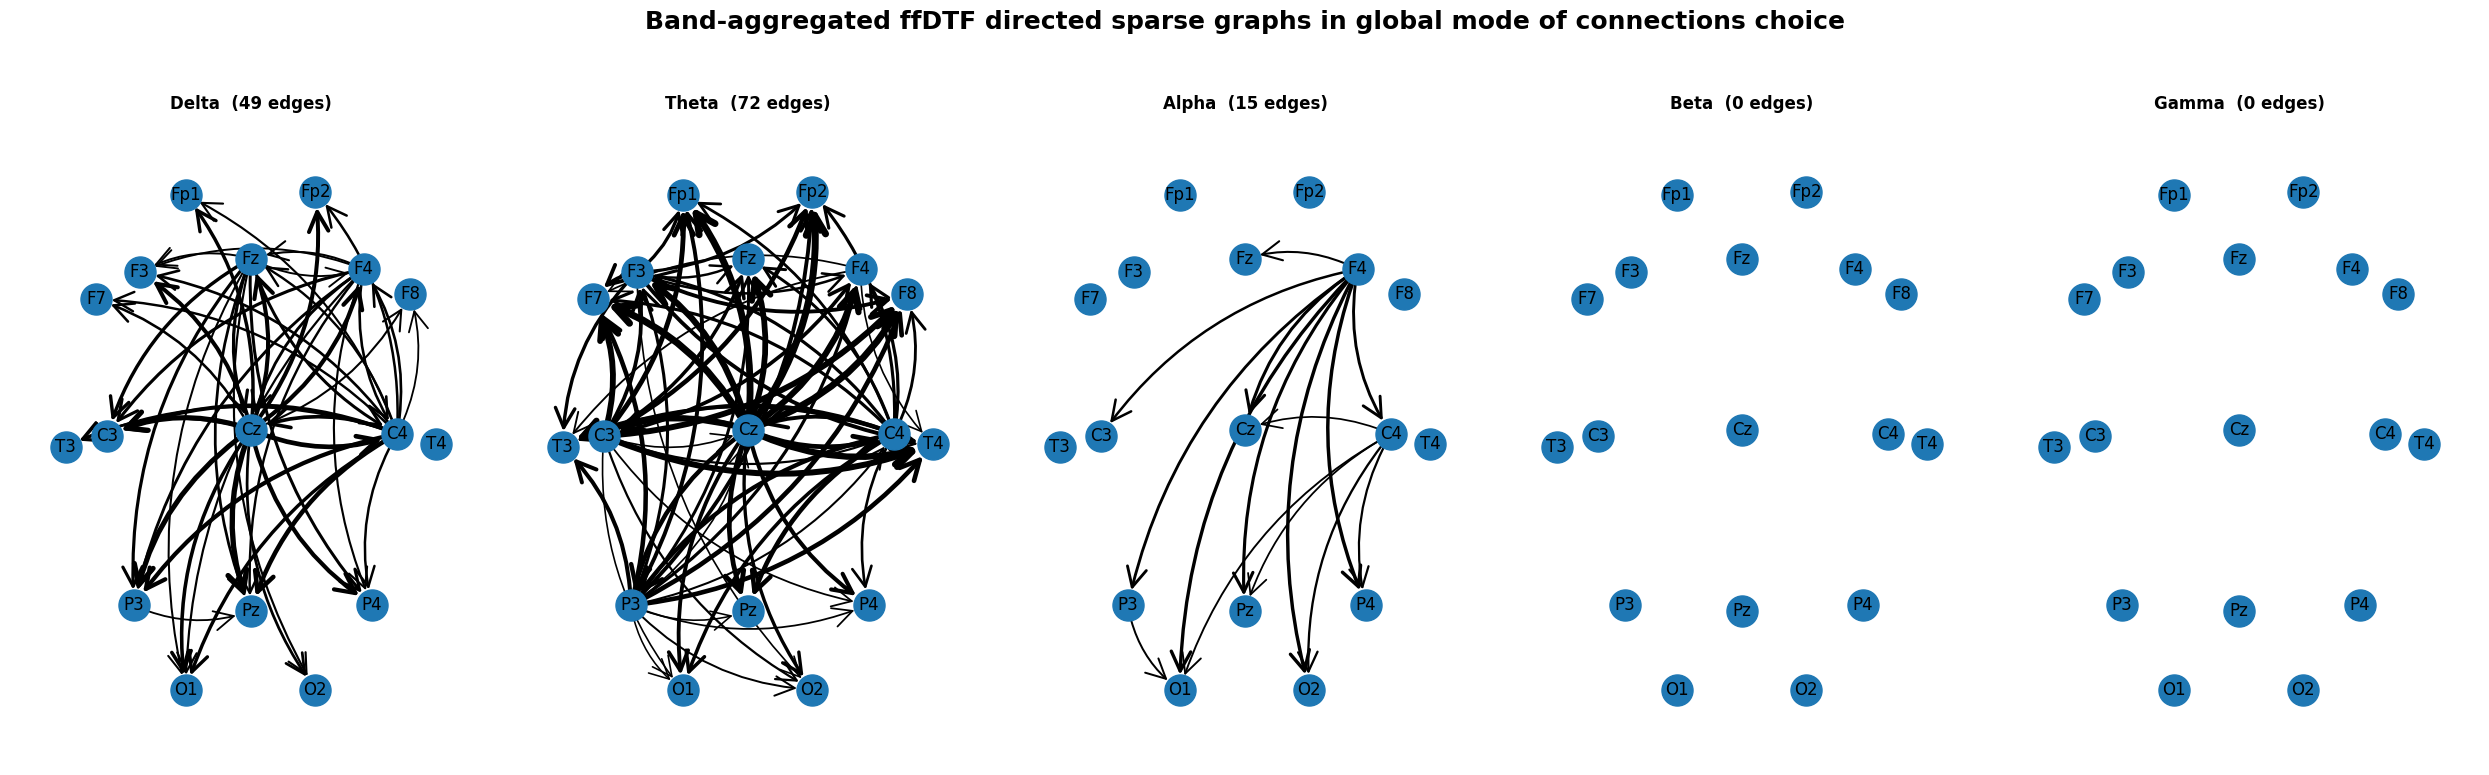

In [81]:
GsSB_ffDTF = graph_bands_sparse(ffDTF_bands, shared_scale = True)
plt.show()

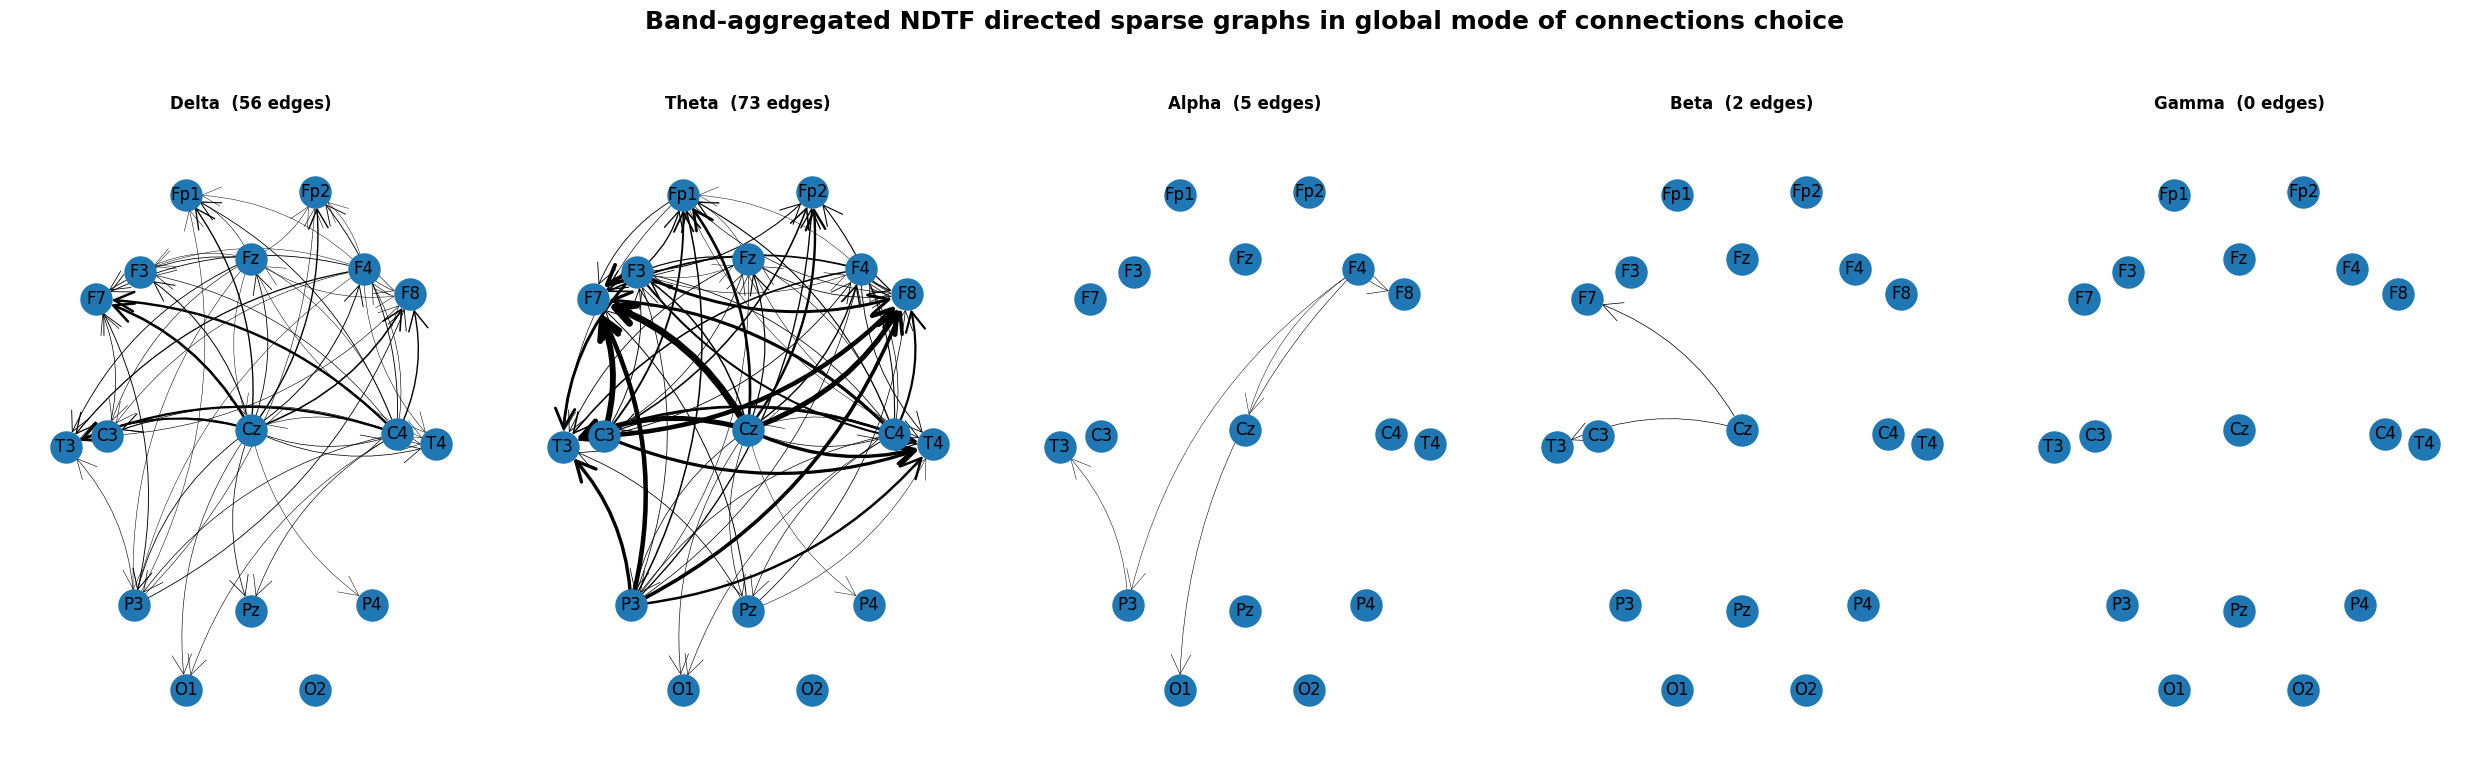

In [82]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'global', conn_name = 'NDTF')
plt.show()